# A1 · Framing - exercise: which slot should we book?

Dr Deepak's last 10 new-patient consults, in minutes. We'll find the slot that costs the clinic least.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

visits = np.array([8, 9, 10, 11, 12, 13, 14, 16, 20, 27])

print("mean  ", visits.mean())
print("median", np.median(visits))
print("P80   ", np.quantile(visits, 0.8))

mean   14.0
median 12.5
P80    16.8


## TODO(you): the cost of a slot

For every visit:
- if it runs **past** the slot, each extra minute costs `OVERRUN_COST`
- if it finishes **early**, each idle minute costs `IDLE_COST`

Return the **total** over all visits.

Hint: `np.maximum(durations - slot, 0)` gives the overrun minutes of each visit. What gives the idle minutes?

In [5]:
#OVERRUN_COST = 4   # per minute a visit runs past its slot (everyone behind waits)
IDLE_COST = 1      # per minute the doctor sits idle

# new overrun cost
OVERRUN_COST = 9

def slot_cost(slot, durations):
    """Total cost of booking `slot` minutes for every visit in `durations`."""
    #total_cost = 0
    # for duration in durations:
    #     if duration > slot:
    #         total_cost += (duration - slot) * OVERRUN_COST
    #     else:
    #         total_cost += (slot - duration) * IDLE_COST
    # return total_cost

    # using numpy
    overrun = np.maximum(durations - slot, 0)
    idle = np.maximum(slot - durations, 0)
    total_cost = np.sum(overrun * OVERRUN_COST + idle * IDLE_COST)
    return total_cost
    # raise NotImplementedError


# Check by hand first: slot 12 should cost 130, and slot 25 should cost 120.
for s in [12, 14, 18, 25]:
    print(f"slot {s:>2} min -> cost {slot_cost(s, visits)}")

slot 12 min -> cost 280
slot 14 min -> cost 210
slot 18 min -> cost 150
slot 25 min -> cost 130


## The cost of every possible slot

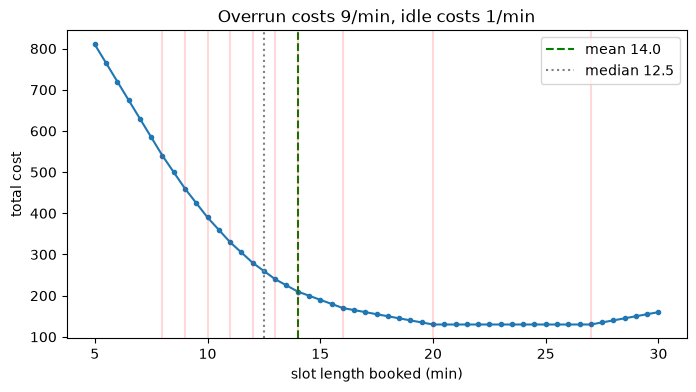

In [6]:
slots = np.arange(5, 30.5, 0.5)
costs = [slot_cost(s, visits) for s in slots]

plt.figure(figsize=(8, 4))
plt.plot(slots, costs, marker=".")
plt.axvline(visits.mean(), color="green", linestyle="--", label=f"mean {visits.mean():.1f}")
plt.axvline(np.median(visits), color="grey", linestyle=":", label=f"median {np.median(visits):.1f}")
for v in visits:
    plt.axvline(v, color="red", alpha=0.15)   # each red line is one visit
plt.xlabel("slot length booked (min)")
plt.ylabel("total cost")
plt.title(f"Overrun costs {OVERRUN_COST}/min, idle costs {IDLE_COST}/min")
plt.legend()
plt.show()

## Questions - write your answers here

1. Which slot is cheapest? The mean, the median, or something else?

   *Answer:* median which is 12.5

2. The curve has a flat bottom. Between which two visit values is it flat? What fraction of visits lies below that flat region?

   *Answer:* curve has a flat bottom betwwen 16 and 20 visit and there is no visit lies below that flat region

3. Predict **before** running: if `OVERRUN_COST = 9`, where does the minimum move? Then change it and check.

   *Prediction:* it will move beyound 20

   *What actually happened:* moved to 20 to 25
   